## Problem Statement
ConnectTel is a telecom company that loses a lot of revenue because customers cancel and switch to competitors. Getting a new customer costs more than keeping an old one. In this project I build a model that predicts which customers are likely to churn, so the retention team can offer them discounts or better plans before they leave. I also explain why customers leave, using SHAP, and give recommendations based on it.

In [219]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [220]:
df=pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [221]:
df.shape

(7043, 21)

In [222]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [223]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [224]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [225]:
#cleaning of data

In [226]:
print(df.isnull().sum())
print("Duplicates: ",df.duplicated().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Duplicates:  0


## Data Cleaning
In this section I check the data for missing values and duplicates, fix the problems I find, and get the target column ready for modeling.

In [227]:
df['TotalCharges']=pd.to_numeric(df["TotalCharges"],errors="coerce")
print(df["TotalCharges"].isnull().sum())

11


### Converting TotalCharges to numbers
TotalCharges was stored as text because some values were blank spaces. I converted the column to numbers using pd.to_numeric with errors="coerce", which turns anything it cannot convert into NaN. Now 11 missing values show up. These were hidden before because a blank space is not counted as null.

In [228]:
df[df["TotalCharges"].isnull()][["tenure","MonthlyCharges","TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


### Why are these 11 values missing?
I looked at only the rows with missing TotalCharges. All 11 customers have tenure = 0, which means they just joined and have not been billed yet. So the blank is not a data error, it simply means they have paid nothing so far.

In [229]:
df["TotalCharges"]=df["TotalCharges"].fillna(0)

### Filling the missing values
I filled the 11 missing TotalCharges values with 0. I did this because these customers have tenure 0, so their total paid is really 0. Filling with the average would be wrong because a brand new customer cannot have paid the average amount. I did not drop these rows because that would waste 11 customers for no reason.

In [230]:
df=df.drop("customerID",axis=1)
df["Churn"]=df["Churn"].map({"Yes": 1,"No":0})

###  Dropping customerID and converting the target
1. I dropped customerID because it is a unique code for each customer and does not help predict churn. Keeping it could make the model memorize customers instead of learning patterns.
2. I converted Churn from Yes/No to 1/0 because models only work with numbers. Here 1 means the customer left and 0 means the customer stayed.

In [231]:
df.info()
print("Churn %:",round(df["Churn"].mean()*100,1))

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

###  Final check and class imbalance
After cleaning, there are no missing values, TotalCharges is now a float, and Churn is now an integer. About 26.5% of customers churned and about 73.5% stayed, so the data is imbalanced. Because of this, accuracy alone can be misleading (a model that says "nobody churns" would still be about 73% accurate). So I will mainly use AUC-ROC, precision, and recall to judge the models.

### Summary of cleaning
1.Converted TotalCharges from text to numbers and found 11 hidden missing values

2.Filled them with 0 because those customers have tenure 0
3.Dropped customerID

4.Converted Churn to 1/0

5.Found that the data is imbalanced (about 26.5% churn)

In [232]:
#plotting one column at a time

In [233]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = df.select_dtypes(include="object").columns.tolist() + ["SeniorCitizen"]
print(cat_cols)

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'SeniorCitizen']


C:\Users\Shaurya\AppData\Local\Temp\ipykernel_14692\2804206755.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.tolist() + ["SeniorCitizen"]


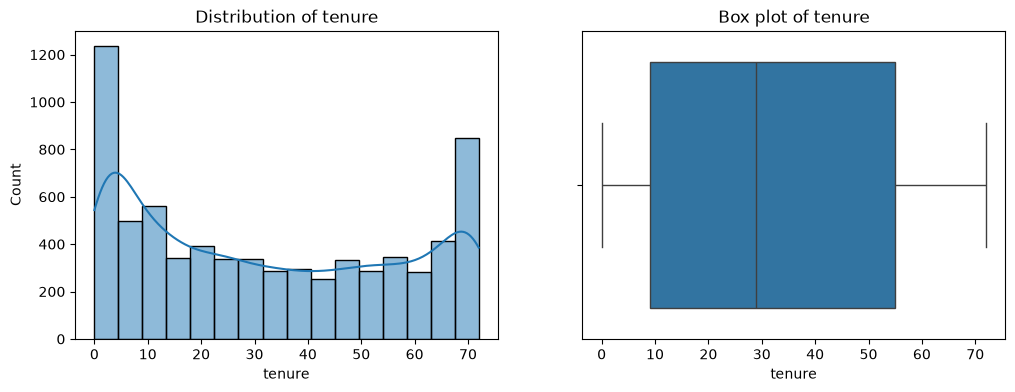

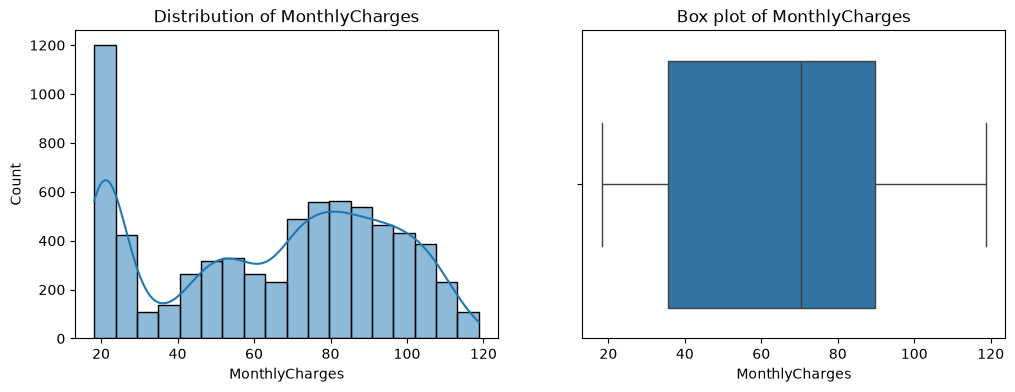

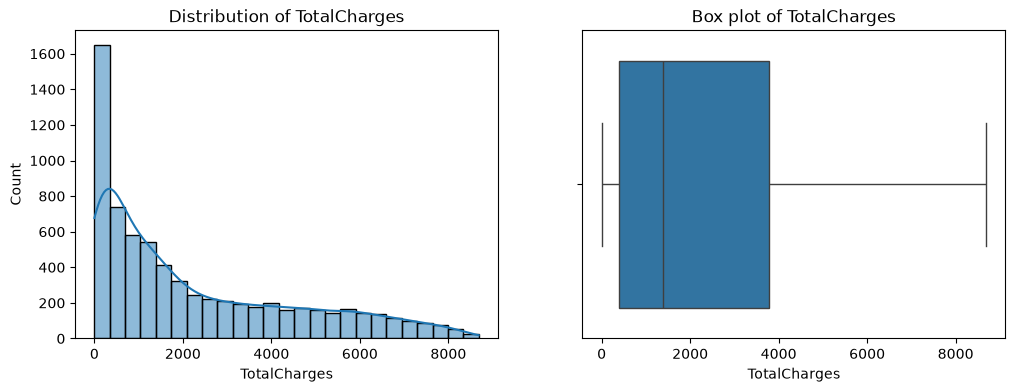

In [234]:
for col in num_cols:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(df[col], kde=True, ax=ax[0])
    sns.boxplot(x=df[col], ax=ax[1])
    ax[0].set_title(f"Distribution of {col}")
    ax[1].set_title(f"Box plot of {col}")
    plt.show()

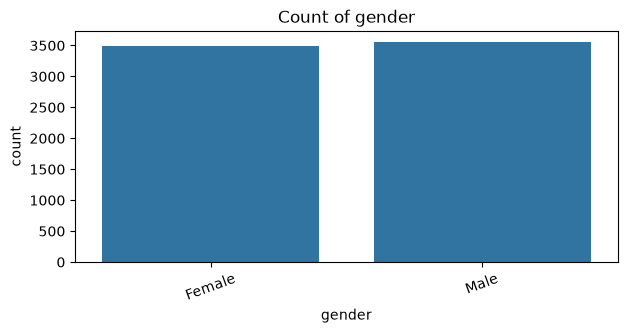

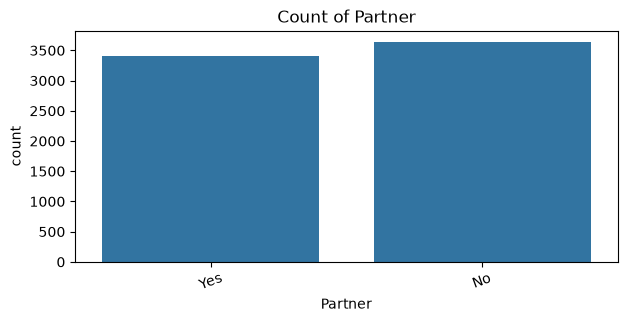

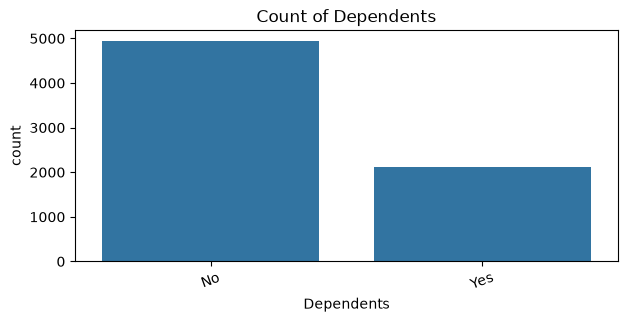

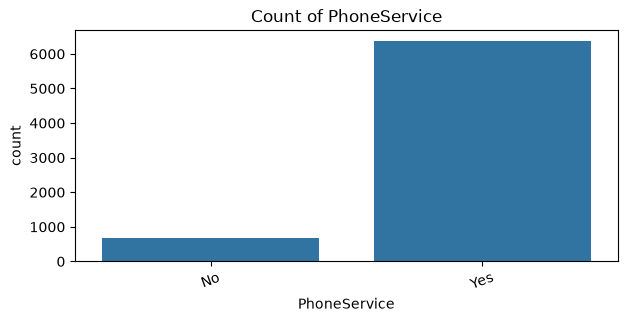

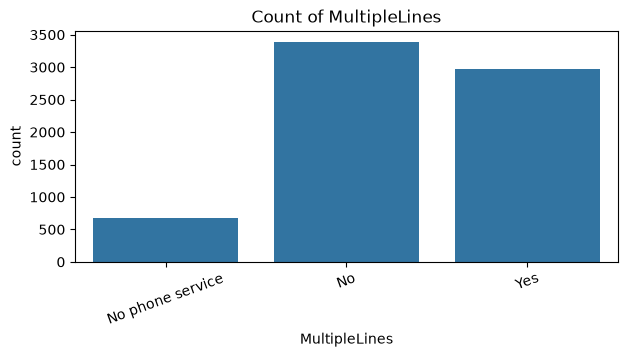

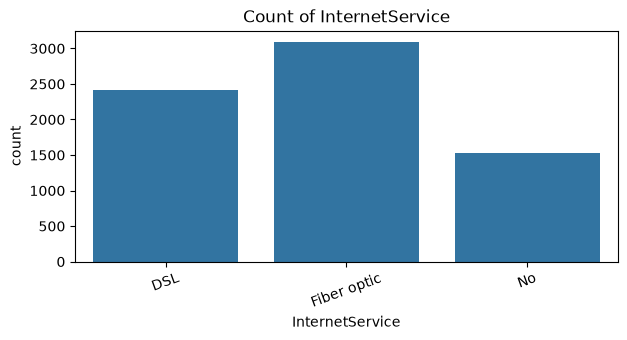

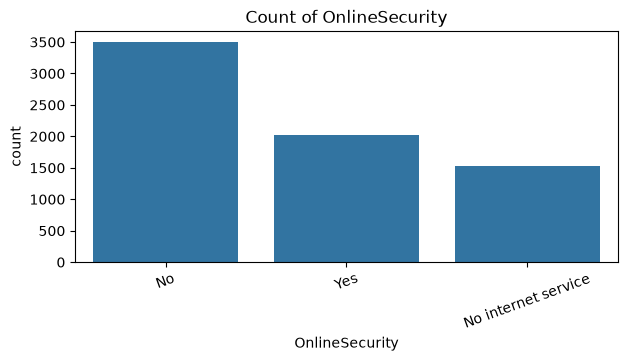

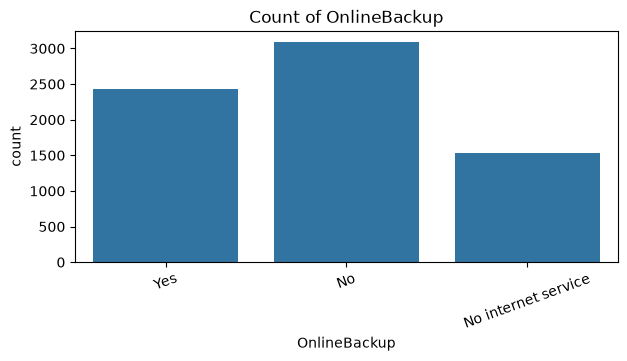

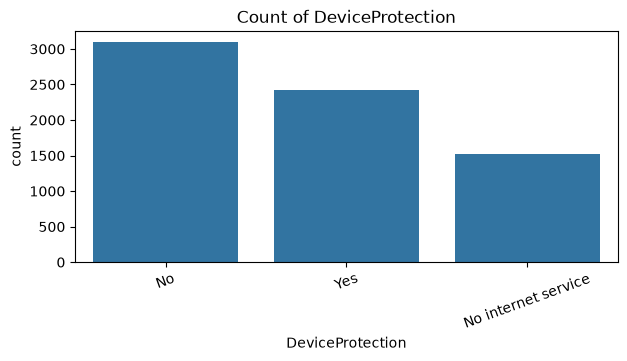

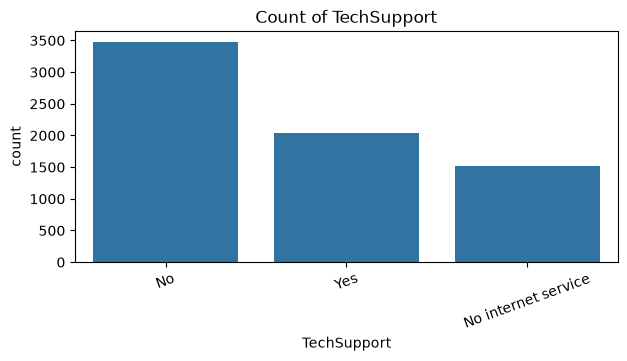

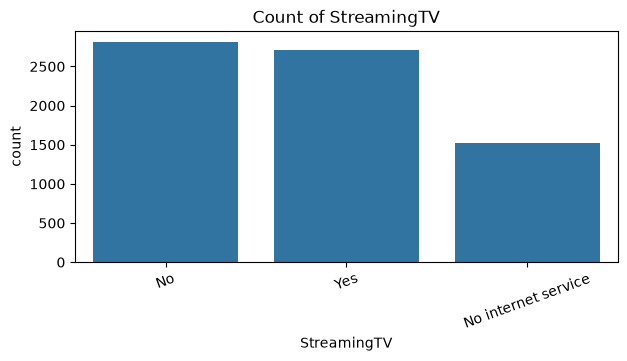

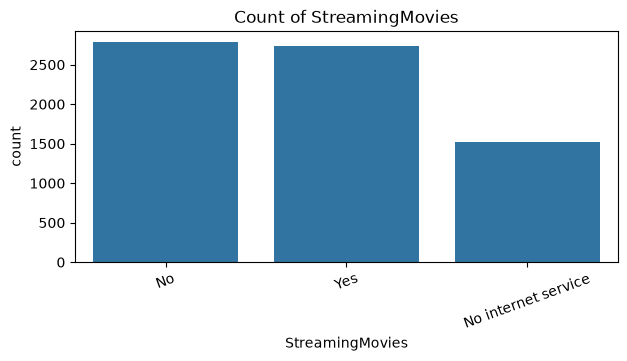

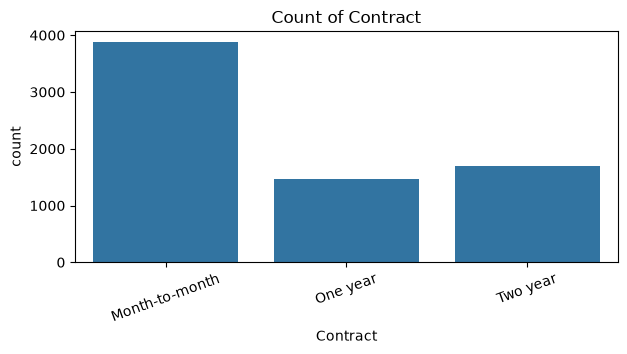

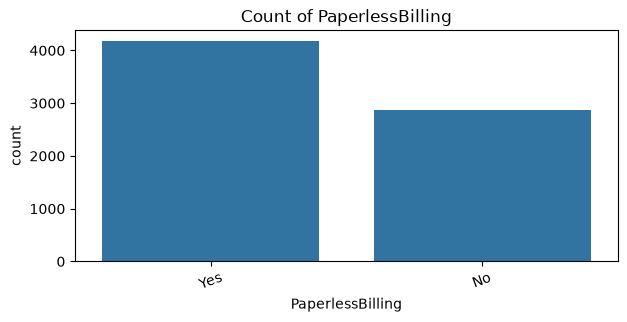

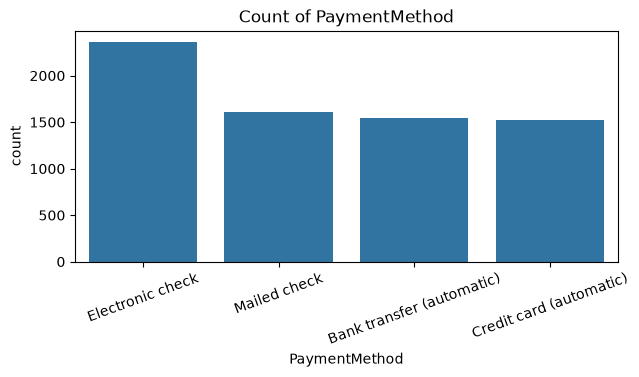

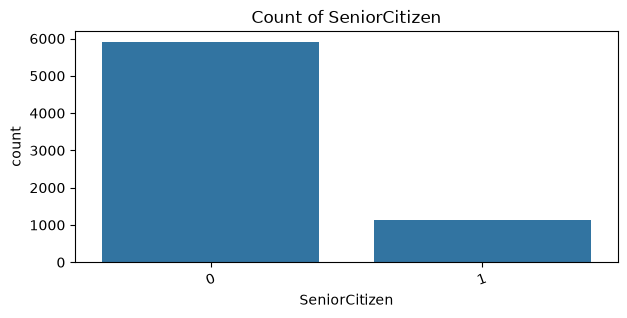

In [235]:
for col in cat_cols:
    plt.figure(figsize=(7,3))
    sns.countplot(x=col,data=df)
    plt.title(f"Count of {col}")
    plt.xticks(rotation=20)
    plt.show()

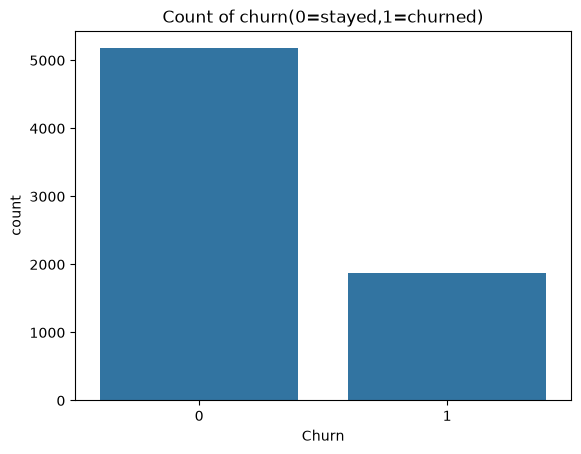

In [236]:
sns.countplot(x="Churn",data=df)
plt.title("Count of churn(0=stayed,1=churned)")
plt.show()

In [237]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = df.select_dtypes(include="object").columns.tolist() + ["SeniorCitizen"]

for col in cat_cols:
    print(df.groupby(col)["Churn"].mean().mul(100).round(1))
    print("-" * 30)

gender
Female    26.9
Male      26.2
Name: Churn, dtype: float64
------------------------------
Partner
No     33.0
Yes    19.7
Name: Churn, dtype: float64
------------------------------
Dependents
No     31.3
Yes    15.5
Name: Churn, dtype: float64
------------------------------
PhoneService
No     24.9
Yes    26.7
Name: Churn, dtype: float64
------------------------------
MultipleLines
No                  25.0
No phone service    24.9
Yes                 28.6
Name: Churn, dtype: float64
------------------------------
InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn, dtype: float64
------------------------------
OnlineSecurity
No                     41.8
No internet service     7.4
Yes                    14.6
Name: Churn, dtype: float64
------------------------------
OnlineBackup
No                     39.9
No internet service     7.4
Yes                    21.5
Name: Churn, dtype: float64
------------------------------
DeviceProtection
No       

C:\Users\Shaurya\AppData\Local\Temp\ipykernel_14692\496309090.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.tolist() + ["SeniorCitizen"]


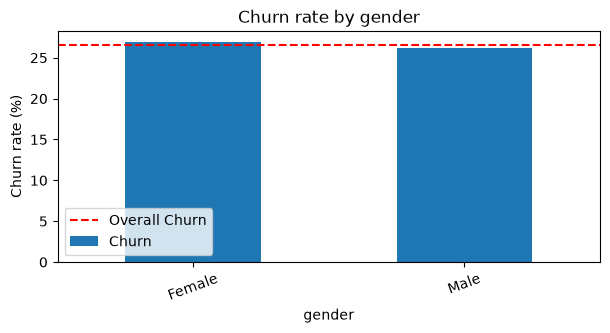

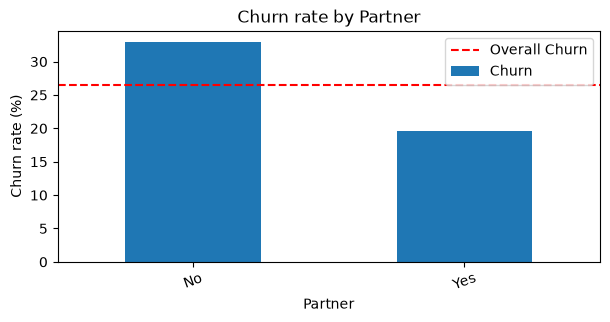

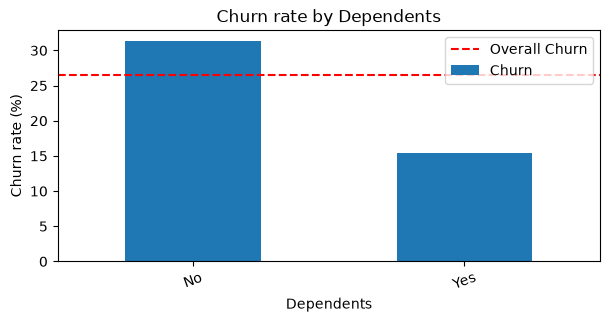

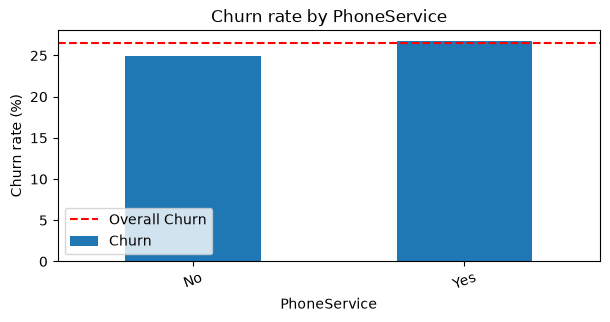

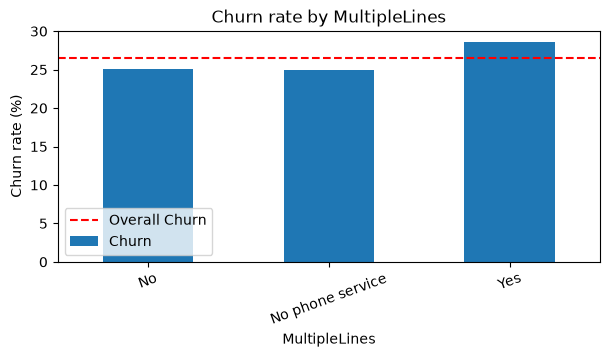

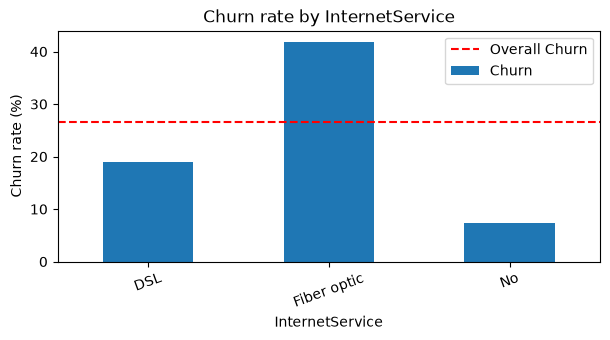

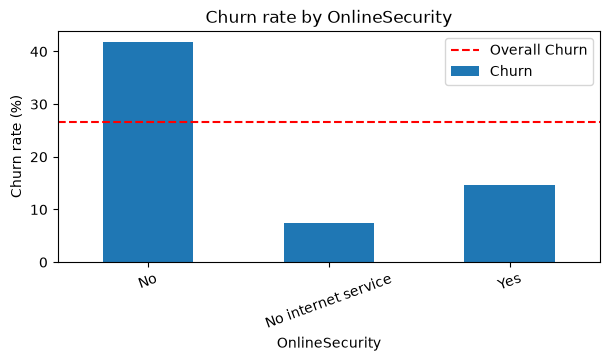

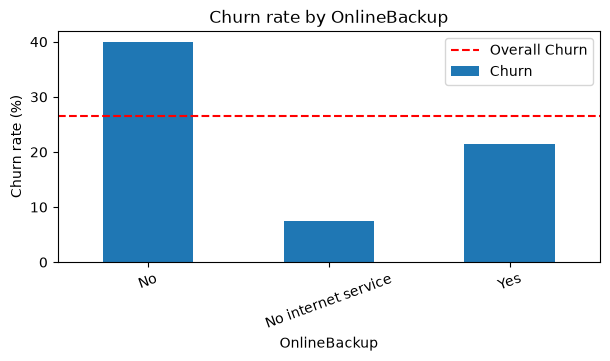

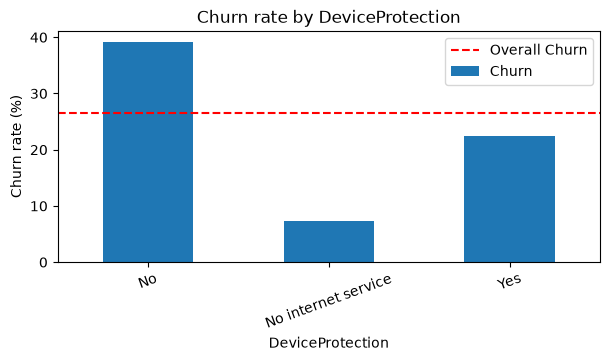

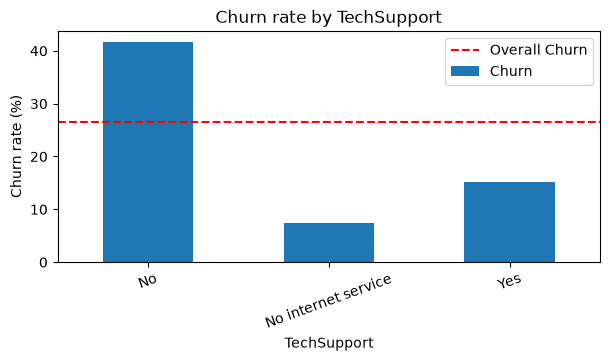

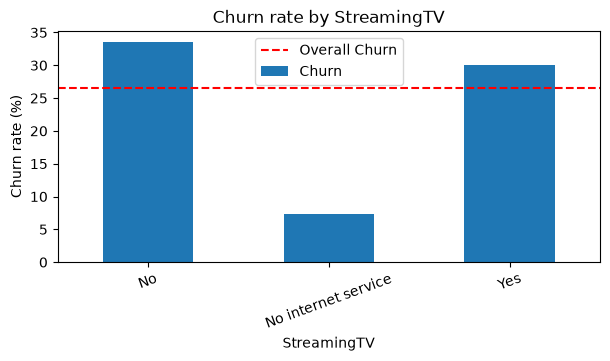

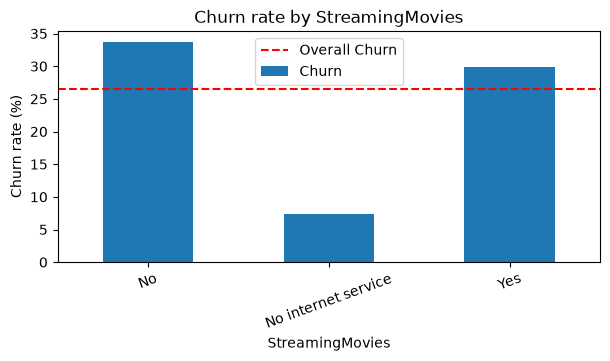

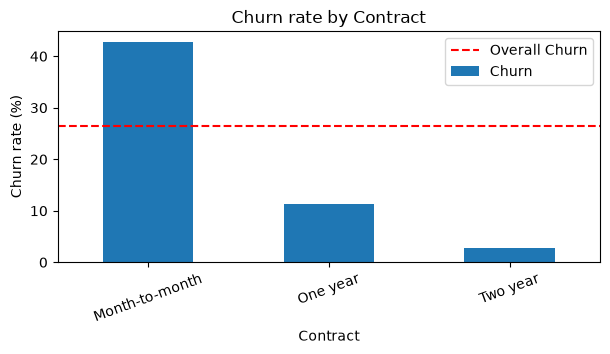

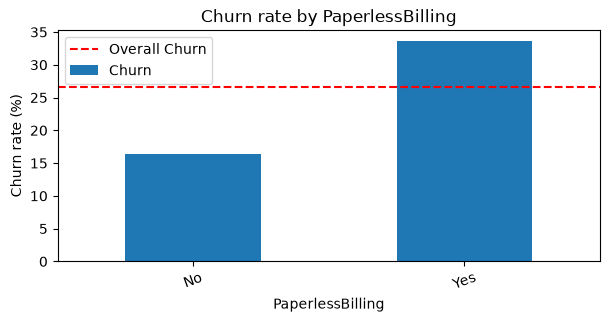

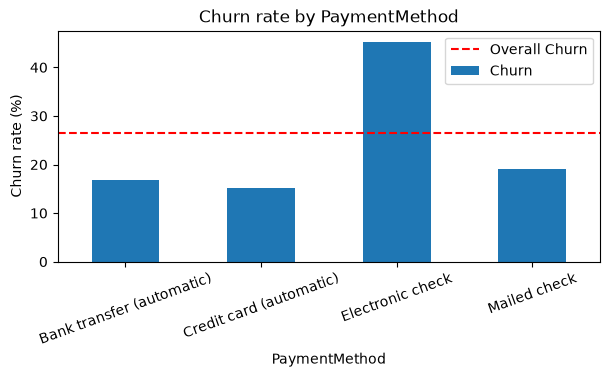

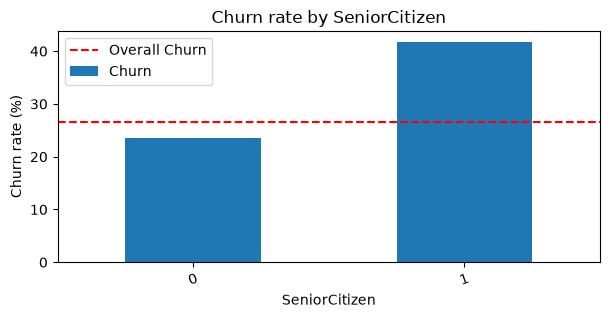

In [238]:
overall=df["Churn"].mean()*100
for col in cat_cols:
    rate=df.groupby(col)["Churn"].mean()*100
    plt.figure(figsize=(7,3))
    rate.plot(kind="bar")
    plt.axhline(overall,color="red",linestyle="--",label="Overall Churn")
    plt.ylabel("Churn rate (%)")
    plt.title(f"Churn rate by {col}")
    plt.xticks(rotation=20)
    plt.legend()
    plt.show()

### Categorical features vs Churn

**Contract:** Month-to-month customers churn at about 42.7%, compared to about 11.3% for one year and about 2.8% for two year contracts. This is the strongest pattern so far. Customers on long contracts are locked in, so they rarely leave.

**InternetService:** Fiber optic customers churn at about 41.9%, which is more than double DSL customers (about 19.0%). Customers with no internet churn the least (about 7.4%).

**PaymentMethod:** Electronic check users churn the most (about 45.3%). The other three methods are much lower, between about 15% and 19%.

**OnlineSecurity and TechSupport:** Customers who do not have these services churn at about 41% to 42%, while customers who have them churn at only about 15%. Customers who take extra services seem more attached to the company.

**SeniorCitizen:** Senior citizens churn at 41.7% compared to 23.6% for non-seniors.

**Partner:** Customers without a partner churn at 33.0% compared to 19.7% for customers with a partner.

**Dependents:** Customers without dependents churn at 31.3% compared to 15.5% for those with dependents, which is about half.

**PaperlessBilling:** Customers with paperless billing churn more (about 33.6%) than those without (about 16.3%).

**gender:** Female customers churn at 26.9% and male customers at 26.2%. This is almost the same, so gender does not help predict churn.

**PhoneService and MultipleLines:** PhoneService shows 24.9% vs 26.7%, and MultipleLines shows 25.0%, 24.9% and 28.6%. These differences are small, so they are weak features.

C:\Users\Shaurya\AppData\Local\Temp\ipykernel_14692\1458278913.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.tolist() + ["SeniorCitizen"]


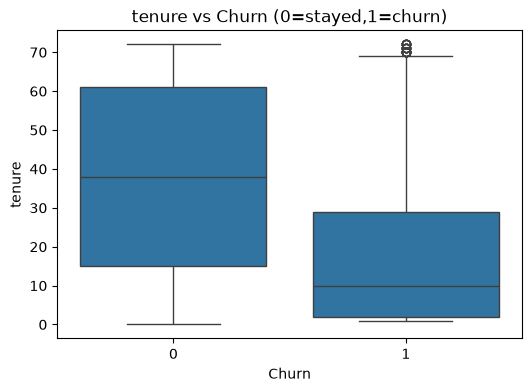

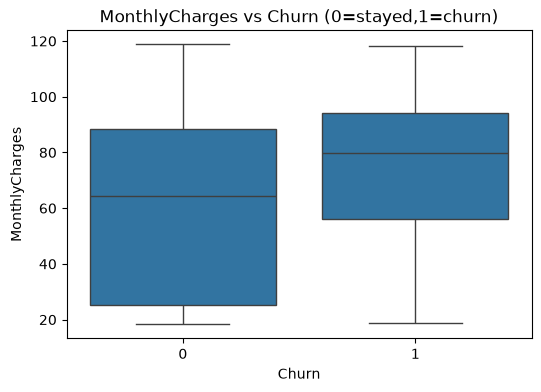

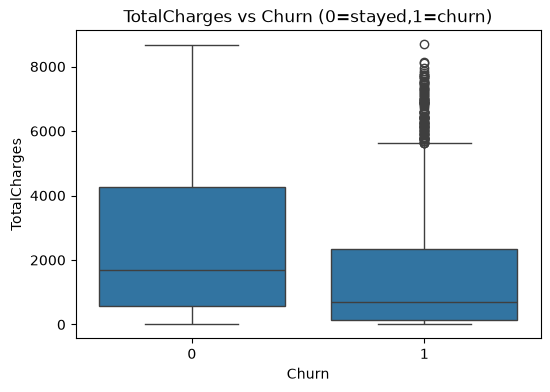

In [239]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = df.select_dtypes(include="object").columns.tolist() + ["SeniorCitizen"]
for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x="Churn",y=col,data=df)
    plt.title(f"{col} vs Churn (0=stayed,1=churn)")
    plt.show()

### Numerical features vs Churn

- **tenure:** Customers who churned have a much lower tenure. Their median is around 10 months, while customers who stayed have a median of around 38 months. So customers mostly leave early.
- **MonthlyCharges:** Customers who churned pay more per month. Their median is around 80, compared to around 65 for customers who stayed.
- **TotalCharges:** Customers who churned have a lower total, mainly because they stayed for a shorter time.

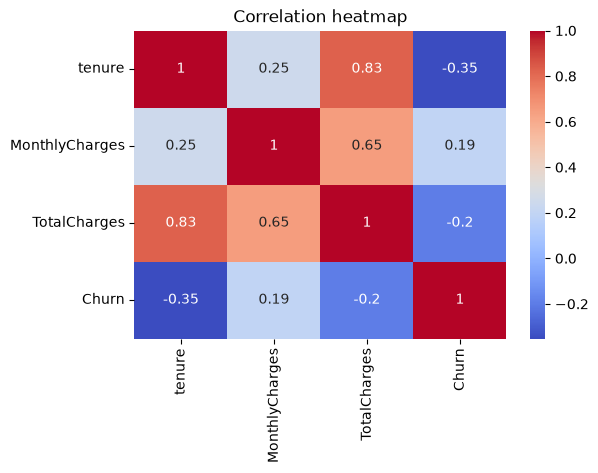

In [240]:
plt.figure(figsize=(6,4))
sns.heatmap(df[num_cols+["Churn"]].corr(),annot=True,cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

### Correlation heatmap
tenure has a negative correlation with Churn (about -0.35), which means longer tenure goes with less churn. MonthlyCharges has a small positive correlation (about 0.19), and TotalCharges has a correlation of about -0.20. TotalCharges and tenure are highly correlated (about 0.83) because TotalCharges keeps growing with time, so these two columns carry similar information.

In [241]:
summary={}
for col in cat_cols:
    rate=df.groupby(col)["Churn"].mean()*100
    summary[col]=round(rate.max()-rate.min(),1)
pd.Series(summary).sort_values(ascending=False)

Contract            39.9
InternetService     34.5
OnlineSecurity      34.4
TechSupport         34.2
OnlineBackup        32.5
DeviceProtection    31.7
PaymentMethod       30.0
StreamingMovies     26.3
StreamingTV         26.1
SeniorCitizen       18.1
PaperlessBilling    17.2
Dependents          15.8
Partner             13.3
MultipleLines        3.7
PhoneService         1.8
gender               0.8
dtype: float64

### Which categorical features matter most
I ranked the categorical columns by the gap between their highest and lowest churn rate. A bigger gap means the column separates churners from non-churners better. The top columns are Contract,InternetService,OnlineSecurity,TechSupport,OnlineBackup, and the bottom ones are gender and PhoneService, which have almost no gap.

### Summary of bivariate analysis
The features most linked to churn are:
1. **Contract:** month-to-month customers churn the most (about 42.7%)
2. **tenure:** customers who churn leave early (median about 10 months)
3. **InternetService:** fiber optic customers churn more than DSL (about 41.9% vs 19.0%)

Other important features are PaymentMethod (electronic check), OnlineSecurity, TechSupport, SeniorCitizen, Partner, Dependents and MonthlyCharges. gender and PhoneService show almost no difference, so they are weak features.

These findings will guide the hypothesis tests in the next section and the new features I create after that.

## Hypothesis Testing
In the bivariate analysis I saw that Fiber optic customers and customers without a partner seem to churn more. Here I use the chi-square test of independence to check if these differences are real or just by chance. I use a significance level of 0.05.

In [242]:
from scipy.stats import chi2_contingency

### Test 1: Do Fiber optic customers churn more than DSL customers?
- **H0 (null):** Churn does not depend on the type of internet service (Fiber optic vs DSL).
- **H1 (alternative):** Churn depends on the type of internet service.
- **Test used:** Chi-square test of independence (both variables are categorical).
- **Significance level:** 0.05

In [243]:
sub=df[df["InternetService"].isin(["DSL","Fiber optic"])]
print("Churn rate (%): ")
print(sub.groupby("InternetService")["Churn"].mean().mul(100).round(1))
table=pd.crosstab(sub["InternetService"],sub["Churn"])
print("\nObserved counts: ")
print(table)

Churn rate (%): 
InternetService
DSL            19.0
Fiber optic    41.9
Name: Churn, dtype: float64

Observed counts: 
Churn               0     1
InternetService            
DSL              1962   459
Fiber optic      1799  1297


I kept only DSL and Fiber optic customers, because customers with no internet are not part of this question. The churn rate for Fiber optic is about 41.9% and for DSL about 19.0%. The table above shows the actual number of customers who stayed (0) and churned (1) in each group. This table is the input for the chi-square test.

In [244]:
chi2,p,dof,expected=chi2_contingency(table)
print("Chi-squared value:",round(chi2,2))
print("p-value:",f"{p:.2e}")
print("Degrees of freedom:",dof)
if(p<0.05):
    print("Reject H0:churn depends on internet service type")
else:
    print("Fail to reject H0:No significant relation")

Chi-squared value: 328.26
p-value: 2.30e-73
Degrees of freedom: 1
Reject H0:churn depends on internet service type


**Result:** The p-value is far below 0.05, so I reject the null hypothesis.

**Conclusion:** Fiber optic customers churn significantly more than DSL customers (about 41.9% vs 19.0%). This difference is real and not by chance. Possible reasons are the higher price of Fiber plans or service quality problems, but I cannot confirm that from this data. This is an important group for the retention team.

### Test 2: Does having a partner reduce churn?
- **H0 (null):** Churn does not depend on whether the customer has a partner.
- **H1 (alternative):** Churn depends on whether the customer has a partner.
- **Test used:** Chi-square test of independence
- **Significance level:** 0.05

In [245]:
print("Churn rate(%):")
print(df.groupby("Partner")["Churn"].mean().mul(100).round(1))

table2=pd.crosstab(df["Partner"],df["Churn"])
print("\nObserved counts:")
print(table2)

Churn rate(%):
Partner
No     33.0
Yes    19.7
Name: Churn, dtype: float64

Observed counts:
Churn       0     1
Partner            
No       2441  1200
Yes      2733   669


Customers without a partner churn at 33.0% and customers with a partner churn at 19.7%, so the gap is about 13 percentage points. The table shows the number of customers in each group.

In [246]:
chi2_2,p2,dof2,expected2=chi2_contingency(table2)

print("Chi-square value:",round(chi2_2,2))
print("p-value:",f"{p2:.2e}")
print("Degrees of freedom:",dof2)

if p2<0.05:
    print("Reject H0:churn depends on having a partner")
else:
    print("Fail to reject H0:No significant relation")

Chi-square value: 158.73
p-value: 2.14e-36
Degrees of freedom: 1
Reject H0:churn depends on having a partner


**Result:** The p-value is far below 0.05, so I reject the null hypothesis.

**Conclusion:** Having a partner is linked with lower churn. Customers without a partner churn more (33.0% vs 19.7%), and this difference is statistically significant. This does not prove that having a partner causes less churn. It may be because customers with partners have shared plans or more stable households.

### Summary of hypothesis testing
- **Fiber optic vs DSL:** Fiber customers churn significantly more (about 41.9% vs 19.0%). H0 rejected.
- **Partner vs no partner:** Customers without a partner churn significantly more (33.0% vs 19.7%). H0 rejected.

Both differences are statistically significant at the 0.05 level, so InternetService and Partner are useful features for the model. Chi-square only shows that a relation exists, not that one thing causes the other.

## Feature Engineering
Raw data is often not enough for a good model. Here I create 3 new features from the existing columns, check that they are useful by comparing them with churn, and keep them for modeling.

In [247]:
df["TotalChargesPerTenure"]=df["TotalCharges"]/(df["tenure"]+1)
df[["tenure","TotalCharges","TotalChargesPerTenure"]].head()

,tenure,TotalCharges,TotalChargesPerTenure
0,1,29.85,14.925000
1,34,1889.50,53.985714
2,2,108.15,36.050000
3,45,1840.75,40.016304
4,2,151.65,50.550000


### TotalChargesPerTenure
This is the total amount a customer has paid divided by the months they have stayed. It shows how much a customer pays per month on average over their whole stay. I used tenure + 1 in the denominator so that new customers with tenure 0 do not cause a division by zero error.

In [248]:
service_cols=["OnlineSecurity","OnlineBackup","DeviceProtection",
              "TechSupport","StreamingTV","StreamingMovies"]
df["ServiceCount"]=(df[service_cols]=="Yes").sum(axis=1)
df["ServiceCount"].value_counts().sort_index()

ServiceCount
0    2219
1     966
2    1033
3    1118
4     852
5     571
6     284
Name: count, dtype: int64

### ServiceCount
This counts how many of the add-on services (OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies) a customer has. The value goes from 0 to 6. The idea is that customers who use more services are more attached to the company. Customers with no internet service also get 0, because they cannot take these add-ons.

In [249]:
df["isMonthToMonth"]=(df["Contract"]=="Month-to-month").astype(int)
df["isMonthToMonth"].value_counts()

isMonthToMonth
1    3875
0    3168
Name: count, dtype: int64

### IsMonthToMonth
This is a simple flag, 1 if the customer is on a month-to-month contract and 0 otherwise. I made it because Contract was one of the strongest patterns in the bivariate analysis, and a 0/1 flag is easy for the model to use.

In [250]:
df[["TotalChargesPerTenure","ServiceCount","isMonthToMonth"]].head(10)

,TotalChargesPerTenure,ServiceCount,isMonthToMonth
0,14.925000,1,1
1,53.985714,2,0
2,36.050000,2,1
3,40.016304,3,0
4,50.550000,0,1
5,91.166667,3,1
6,84.756522,2,1
7,27.445455,1,1
8,105.036207,4,1
9,55.364286,2,0


The three new columns are created and have no missing values. Next I compare each one with Churn to check if it is useful.

ServiceCount
0    21.4
1    45.8
2    35.8
3    27.4
4    22.3
5    12.4
6     5.3
Name: Churn, dtype: float64


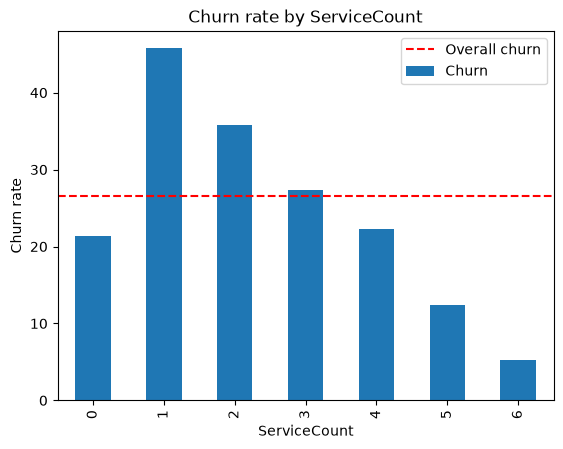

In [251]:
print(df.groupby("ServiceCount")["Churn"].mean().mul(100).round(1))
(df.groupby("ServiceCount")["Churn"].mean()*100).plot(kind="bar")
plt.axhline(df["Churn"].mean()*100,color="red",linestyle="--",label="Overall churn")
plt.ylabel("Churn rate")
plt.title("Churn rate by ServiceCount")
plt.legend()
plt.show()

### ServiceCount vs Churn
Churn rate generally goes down as the number of add-on services goes up. Customers with 5 or 6 services churn very little, while customers with fewer services churn more. The group with 0 services is a mix of two types, customers with no internet (who rarely churn) and customers with internet but no add-ons (who churn a lot), so that bar can look different from the trend. Overall, ServiceCount looks useful.

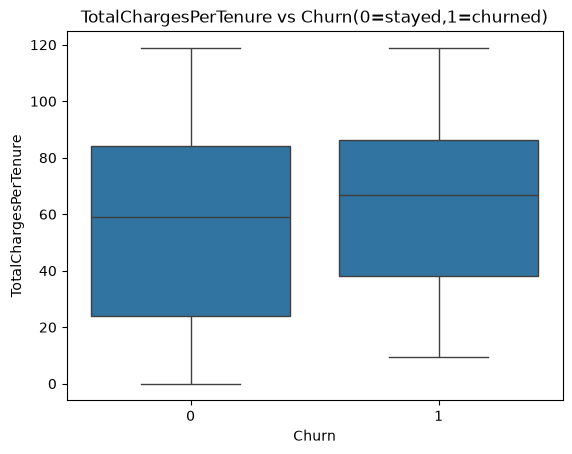

Churn
0    59.2
1    66.6
Name: TotalChargesPerTenure, dtype: float64


In [252]:
sns.boxplot(x="Churn",y="TotalChargesPerTenure",data=df)
plt.title("TotalChargesPerTenure vs Churn(0=stayed,1=churned)")
plt.show()
print(df.groupby("Churn")["TotalChargesPerTenure"].median().round(1))

### TotalChargesPerTenure vs Churn
The box plot compares the feature for customers who stayed and customers who churned. Customers who churned have a higher median, which means they pay more per month on average. This matches what I saw earlier with MonthlyCharges. The feature is useful, but it is similar to MonthlyCharges, so it may not add a lot of new information.

isMonthToMonth
0     6.8
1    42.7
Name: Churn, dtype: float64


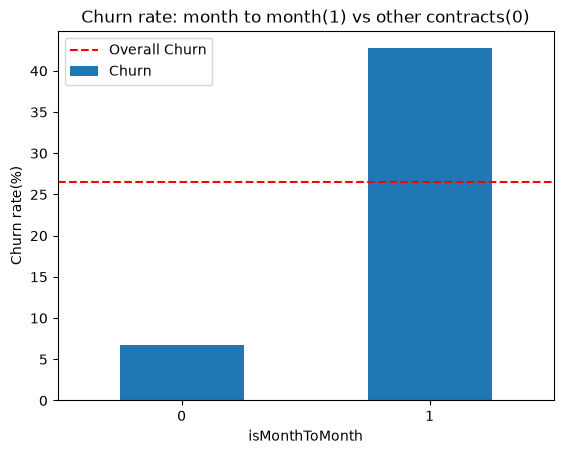

In [253]:
print(df.groupby("isMonthToMonth")["Churn"].mean().mul(100).round(1))


(df.groupby("isMonthToMonth")["Churn"].mean()*100).plot(kind="bar")
plt.axhline(df["Churn"].mean()*100,color="red",linestyle="--",label="Overall Churn")
plt.ylabel("Churn rate(%)")
plt.title("Churn rate: month to month(1) vs other contracts(0)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

### IsMonthToMonth vs Churn
Customers on a month-to-month contract (1) churn at about 42.7%, while customers on one year or two year contracts (0) churn at a much lower rate 6.8%. This is a very clear difference, so this flag is a strong feature.

In [254]:
new_features=["TotalChargesPerTenure","ServiceCount","isMonthToMonth"]
df[new_features+["Churn"]].corr()["Churn"].round(2)

TotalChargesPerTenure    0.07
ServiceCount            -0.09
isMonthToMonth           0.41
Churn                    1.00
Name: Churn, dtype: float64

### Correlation of new features with Churn
IsMonthToMonth has the strongest correlation with Churn among the new features (0.41). ServiceCount and TotalChargesPerTenure are weaker (-0.09 for ServiceCount and 0.07 for TotalChargesPerTenure). Correlation only measures straight line links, so I still rely on the plots above to judge the features.

### Summary of feature engineering
I created three new features:
- **TotalChargesPerTenure:** average amount paid per month over the whole stay
- **ServiceCount:** number of add-on services a customer has (0 to 6)
- **IsMonthToMonth:** 1 if the customer is on a month-to-month contract, 0 otherwise

All three show a link with churn, and IsMonthToMonth is the strongest. These features are added to the dataframe and will be used in modeling after encoding and scaling.

## Data Preparation for Modeling
Models only understand numbers, and some models work better when numbers are on a similar scale. In this section I encode the text columns, split the data into train and test sets, and scale the numerical columns.

In [255]:
df_model=df.copy()
df_model=df_model.replace({"No internet service":"No","No phone service":"No"})

print(df_model["MultipleLines"].value_counts())
print(df_model["OnlineSecurity"].value_counts())

MultipleLines
No     4072
Yes    2971
Name: count, dtype: int64
OnlineSecurity
No     5024
Yes    2019
Name: count, dtype: int64


### Merging similar values
Columns like OnlineSecurity and MultipleLines had three values: Yes, No, and "No internet service" or "No phone service". The third value means the same as No for the model, because the customer does not have that service. I merged them so that encoding does not create extra useless columns. I worked on a copy called df_model so the original df stays safe.

In [256]:
cat_to_encode=df_model.select_dtypes(include="object").columns.tolist()
print(cat_to_encode)
df_model=pd.get_dummies(df_model,columns=cat_to_encode,drop_first=True)
bool_cols=df_model.select_dtypes(include="bool").columns
df_model[bool_cols]=df_model[bool_cols].astype(int)
print(df_model.shape)
df_model.head()

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
(7043, 27)


C:\Users\Shaurya\AppData\Local\Temp\ipykernel_14692\1770113517.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_to_encode=df_model.select_dtypes(include="object").columns.tolist()


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,TotalChargesPerTenure,ServiceCount,isMonthToMonth,gender_Male,Partner_Yes,...,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,14.925000,1,1,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,53.985714,2,0,1,0,...,1,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,36.050000,2,1,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,40.016304,3,0,1,0,...,1,1,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,50.550000,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


### One-hot encoding
I converted all text columns into 0/1 columns using one-hot encoding. For example, Contract becomes two columns (Contract_One year and Contract_Two year), and month-to-month is shown when both are 0. I used drop_first=True so that one column per category is dropped, which avoids repeating the same information. The dataset now has 27 columns and all of them are numbers.

In [257]:
print(df_model.dtypes.value_counts())
print("Missing values:",df_model.isnull().sum().sum())

int64      24
float64     3
Name: count, dtype: int64
Missing values: 0


### Checking the encoded data
All columns are now numbers (int or float) and there are no missing values, so the data is ready to be given to a model.

In [258]:
from sklearn.model_selection import train_test_split
X=df_model.drop("Churn",axis=1)
Y=df_model["Churn"]
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42,stratify=Y)

print("Train shape:",X_train.shape)
print("Test shape:",X_test.shape)
print("Train churn %:",round(Y_train.mean()*100,1))
print("Test churn %:",round(Y_test.mean()*100,1))

Train shape: (5634, 26)
Test shape: (1409, 26)
Train churn %: 26.5
Test churn %: 26.5


### Train and test split
X has all the features and y is the Churn column. I used 80% of the data for training and 20% for testing. I used stratify=y so that both sets keep the same churn percentage (about 26.5%), which is important because the data is imbalanced. random_state=42 makes the split the same every time I run it. The train set has 5634 customers and the test set has 1409 customers.

In [259]:
from sklearn.preprocessing import StandardScaler
scale_cols=["tenure","MonthlyCharges","TotalCharges","TotalChargesPerTenure","ServiceCount"]
scaler=StandardScaler()
X_train_s=X_train.copy()
X_test_s=X_test.copy()

X_train_s[scale_cols]=scaler.fit_transform(X_train[scale_cols])
X_test_s[scale_cols]=scaler.transform(X_test[scale_cols])
X_train_s[scale_cols].describe().round(2)

,tenure,MonthlyCharges,TotalCharges,TotalChargesPerTenure,ServiceCount
count,5634.00,5634.00,5634.00,5634.00,5634.00
mean,-0.00,-0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-1.32,-1.54,-1.01,-1.93,-1.11
25%,-0.96,-0.97,-0.83,-1.08,-1.11
50%,-0.14,0.18,-0.40,0.07,-0.03
75%,0.92,0.83,0.67,0.85,0.51
max,1.61,1.79,2.80,1.95,2.13


### Scaling
I scaled the numerical columns (tenure, MonthlyCharges, TotalCharges, TotalChargesPerTenure, ServiceCount) with StandardScaler. After scaling, each column has a mean of about 0 and a standard deviation of about 1, which the table above confirms.

I fit the scaler on the training data only and then used the same scaler on the test data. If I fit it on all the data, information from the test set would leak into training and the results would look better than they really are.

The scaled data (X_train_s and X_test_s) will be used for Logistic Regression. Tree models like Random Forest and XGBoost do not depend on the scale of features, so they will use the unscaled X_train and X_test.

### Summary of data preparation
- Merged "No internet service" and "No phone service" into "No"
- One-hot encoded all text columns, with no missing values left
- Split the data 80/20 with stratify so the churn ratio is the same in both sets
- Scaled the numerical columns, fitting the scaler on the training data only

I now have four datasets: X_train and X_test (unscaled, for tree models), and X_train_s and X_test_s (scaled, for Logistic Regression), with Y_train and Y_test as the targets.

## Model: Logistic Regression
Logistic Regression is my baseline model. It is simple, fast, and shows the linear relation between each feature and churn. Later models will be compared against it.

In [260]:
from sklearn.linear_model import LogisticRegression

lr=LogisticRegression(max_iter=1000)
lr.fit(X_train_s,Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

### Training the model
I trained Logistic Regression on the scaled training data (X_train_s), because this model is sensitive to the scale of features. max_iter=1000 gives the model enough steps to finish learning.

In [261]:
lr_pred=lr.predict(X_test_s)
lr_prob=lr.predict_proba(X_test_s)[:,-1]

print(lr_pred[:10])
print(lr_prob[:10].round(2))

[0 1 0 0 0 1 0 0 0 0]
[0.04 0.57 0.06 0.33 0.03 0.6  0.45 0.14 0.   0.33]


### Making predictions
predict gives the final class for each customer (0 = stays, 1 = churns). predict_proba gives the probability of churn, and I take the second column ([:, 1]) because that is the probability of class 1. I need the probabilities to calculate AUC-ROC and to plot the ROC curve later.

In [262]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,classification_report)
def evaluate(name,Y_true,pred,prob):
    return {
        "Model":name,
        "Accuracy":round(accuracy_score(Y_true,pred),3),
        "Precision":round(precision_score(Y_true,pred),3),
        "Recall":round(recall_score(Y_true,pred),3),
        "F1":round(f1_score(Y_true,pred),3),
        "AUC":round(roc_auc_score(Y_true,prob),3),
    }
results=[evaluate("Logistic Regression",Y_test,lr_pred,lr_prob)]
print(pd.DataFrame(results))
print()
print(classification_report(Y_test,lr_pred))

                 Model  Accuracy  Precision  Recall     F1    AUC
0  Logistic Regression     0.809      0.679   0.532  0.597  0.847

              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.68      0.53      0.60       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.74      1409
weighted avg       0.80      0.81      0.80      1409



### Logistic Regression results
- **Accuracy:** about (0.809). It looks good, but accuracy is misleading here because about 73% of customers stay, so a model that always says "stays" would already get about 73%.
- **Precision:** (0.679). Out of all customers the model flagged as churn, this fraction really churned.
- **Recall:** (0.532). Out of all customers who really churned, this fraction was caught. This is lower than accuracy, so the model misses many churners.
- **AUC:** (0.847). This is my baseline score that the other models need to beat.

In [263]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(Y_test,lr_pred))

[[941  94]
 [175 199]]


### Confusion matrix for Logistic Regression
The top left number is customers correctly predicted as stayed, and the bottom right is customers correctly predicted as churned. The bottom left is churners that the model missed (false negatives), which is 175 customers. These are the costly mistakes, because the company loses them without a chance to react. The top right is customers who would have stayed but were flagged (false positives), which is 94 customers.

In [264]:
coef=pd.Series(lr.coef_[0],index=X_train_s.columns).sort_values()
print("Features that reduce churn: ")
print(coef.head(5).round(2))
print()
print("Features that increase churn: ")
print(coef.tail(5).round(2))

Features that reduce churn: 
InternetService_No      -1.16
Contract_Two year       -1.08
TotalChargesPerTenure   -1.05
tenure                  -0.95
OnlineSecurity_Yes      -0.51
dtype: float64

Features that increase churn: 
ServiceCount                   0.42
MultipleLines_Yes              0.45
TotalCharges                   0.48
isMonthToMonth                 0.52
InternetService_Fiber optic    1.31
dtype: float64


### What the coefficients show
A negative coefficient means the feature lowers the chance of churn, and a positive one raises it. The strongest features that lower churn are (InternetService_No,Contract_Two year,TotalChargesPerTenure,tenure,OnlineSecurity_Yes), and the strongest that raise churn are (ServiceCount,MultipleLines_Yes,TotalCharges,IsMonthToMonth). This agrees with the EDA, for example longer tenure and longer contracts reduce churn. Some coefficients can look odd, because related features (tenure, TotalCharges and TotalChargesPerTenure) share information, so I should not read each one alone.

## Model: Random Forest
Random Forest is an ensemble of many decision trees. Each tree votes and the majority wins. It can capture non-linear patterns and interactions between features that Logistic Regression cannot.

In [265]:
from sklearn.ensemble import RandomForestClassifier
rf=RandomForestClassifier(n_estimators=100,random_state=42)
rf.fit(X_train,Y_train)
rf_pred=rf.predict(X_test)
rf_prob=rf.predict_proba(X_test)[:,-1]

### Training the model
I trained Random Forest with 100 trees on the unscaled training data (X_train), because tree models do not depend on the scale of features. random_state=42 keeps the results the same every time I run it.

In [266]:
results.append(evaluate("Random Forest",Y_test,rf_pred,rf_prob))
print(pd.DataFrame(results))
print()
print(classification_report(Y_test,rf_pred))

                 Model  Accuracy  Precision  Recall     F1    AUC
0  Logistic Regression     0.809      0.679   0.532  0.597  0.847
1        Random Forest     0.787      0.621   0.508  0.559  0.821

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.51      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



### Random Forest results
Random Forest has an accuracy of 0.787, precision of 0.621, recall of 0.508 and AUC of 0.821. Compared to Logistic Regression (AUC 0.847), it is slightly worse. Its recall for churners is still low, so it also misses many churners. With default settings it is not better than the simple baseline, which is common on this dataset.

In [267]:
print(confusion_matrix(Y_test,rf_pred))

[[919 116]
 [184 190]]


### Confusion matrix for Random Forest
Compared to Logistic Regression, which missed 175 churners, Random Forest is slightly worse at catching churners.

TotalCharges                      0.142
tenure                            0.138
TotalChargesPerTenure             0.138
MonthlyCharges                    0.137
isMonthToMonth                    0.069
InternetService_Fiber optic       0.037
PaymentMethod_Electronic check    0.034
ServiceCount                      0.032
PaperlessBilling_Yes              0.024
gender_Male                       0.023
dtype: float64


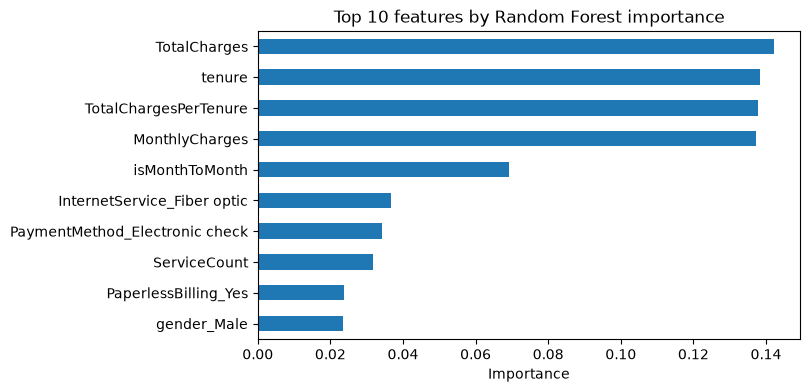

In [268]:
importance=pd.Series(rf.feature_importances_,index=X_train.columns).sort_values(ascending=False)
print(importance.head(10).round(3))
importance.head(10).sort_values().plot(kind="barh",figsize=(7,4))
plt.title("Top 10 features by Random Forest importance")
plt.xlabel("Importance")
plt.show()

### Feature importance
This shows which features the trees used most to split customers. The top features are TotalCharges,tenure,TotalChargesPerTenure,MonthlyCharges,isMonthToMonth. This agrees with my EDA. Feature importance does not show the direction (whether a feature raises or lowers churn), so I will use SHAP later for that.

In [269]:
from sklearn.model_selection import StratifiedKFold,cross_val_score
skf=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
cv_lr=cross_val_score(LogisticRegression(max_iter=1000),
                    X_train_s,Y_train,cv=skf,scoring="roc_auc")
cv_rf=cross_val_score(RandomForestClassifier(n_estimators=100,random_state=42),
                    X_train,Y_train,cv=skf,scoring="roc_auc")
print("Logistic Regression")
print("Fold scores: ",cv_lr.round(3))
print("Mean: ",cv_lr.mean().round(3),"Std: ",cv_lr.std().round(3))
print()
print("Random Forest")
print("Fold scores: ",cv_rf.round(3))
print("Mean: ",cv_rf.mean().round(3),"Std: ",cv_rf.std().round(3))

Logistic Regression
Fold scores:  [0.847 0.83  0.844 0.865 0.857]
Mean:  0.849 Std:  0.012

Random Forest
Fold scores:  [0.819 0.813 0.838 0.826 0.845]
Mean:  0.828 Std:  0.012


### Cross-validation
I used 5-fold stratified cross-validation on the training data. The data is split into 5 parts. The model trains on 4 parts and is tested on the remaining part, and this is repeated 5 times so every part is used for testing once. I used stratified folds so each fold keeps the same churn ratio, and I used AUC as the score.

- **Logistic Regression:** mean AUC 0.849, standard deviation 0.012
- **Random Forest:** mean AUC 0.828, standard deviation 0.012

The standard deviations are small, which means the models give stable results on different parts of the data and are not just lucky on one split.We conclude that Logistic Regression model has a higher mean.

In [270]:
comparison=pd.DataFrame(results)
comparison["CV AUC(mean)"]=[round(cv_lr.mean(),3),round(cv_rf.mean(),3)]
comparison

,Model,Accuracy,Precision,Recall,F1,AUC,CV AUC(mean)
0,Logistic Regression,0.809,0.679,0.532,0.597,0.847,0.849
1,Random Forest,0.787,0.621,0.508,0.559,0.821,0.828


### Comparison so far
The table puts both models side by side with test metrics and cross-validation AUC. Both models have low recall for churners, which I will try to improve in the next steps by handling class imbalance and tuning.

### Summary of Random Forest and cross-validation
Random Forest reached an AUC of 0.821, compared to 0.847 for Logistic Regression. Cross-validation shows that both models are stable. Both miss many churners because the data is imbalanced, so recall is the main thing to improve next.

## Evaluation: Confusion Matrix and ROC Curve
These two plots show where each model is right and wrong, and how well it separates churners from non-churners.

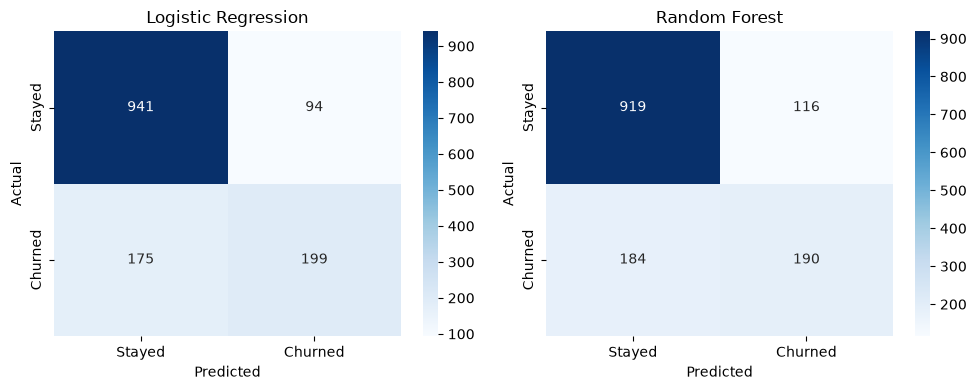

In [271]:
from sklearn.metrics import roc_curve
fig,ax=plt.subplots(1,2,figsize=(10,4))
for a,(name,pred) in zip(ax,[("Logistic Regression",lr_pred),("Random Forest",rf_pred)]):
    sns.heatmap(confusion_matrix(Y_test,pred),annot=True,fmt="d",cmap="Blues",
    xticklabels=["Stayed","Churned"],yticklabels=["Stayed","Churned"],ax=a)
    a.set_title(name)
    a.set_xlabel("Predicted")
    a.set_ylabel("Actual")
plt.tight_layout()
plt.show()

### Confusion matrices
Each box shows a number of customers. Top left is customers correctly predicted as stayed, bottom right is customers correctly predicted as churned. Bottom left (false negatives) are customers who left but the model said they would stay. These are the most costly mistakes, because the company loses them without a chance to react. Top right (false positives) are customers who would have stayed but were flagged, which wastes a discount.

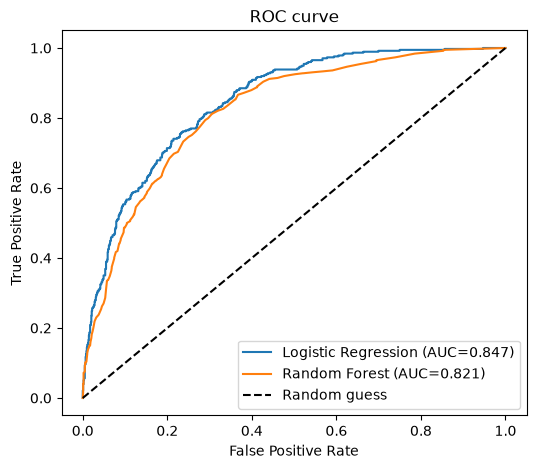

In [272]:
plt.figure(figsize=(6,5))
for name,prob in [("Logistic Regression",lr_prob),("Random Forest",rf_prob)]:
    fpr,tpr,_=roc_curve(Y_test,prob)
    plt.plot(fpr,tpr,label=f"{name} (AUC={roc_auc_score(Y_test,prob):.3f})")
plt.plot([0,1],[0,1],"k--",label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve")
plt.legend()
plt.show()

### ROC curve
The ROC curve shows the trade-off between catching churners (true positive rate) and raising false alarms (false positive rate) at different thresholds. A curve closer to the top left corner is better, and the dashed line is random guessing. Both models are well above the dashed line. Logistic Regression has the higher curve (AUC 0.847 vs 0.821 for Random Forest).

## Handling Class Imbalance
Only about 26.5% of customers churn, so models tend to favor the majority class (stayed) and miss churners. I use class weights so that mistakes on churners are punished more.

In [273]:
lr_bal=LogisticRegression(max_iter=1000,class_weight="balanced")
lr_bal.fit(X_train_s,Y_train)
lr_bal_pred=lr_bal.predict(X_test_s)
lr_bal_prob=lr_bal.predict_proba(X_test_s)[:,1]


rf_bal=RandomForestClassifier(n_estimators=100,random_state=42,class_weight="balanced")
rf_bal.fit(X_train,Y_train)
rf_bal_pred=rf_bal.predict(X_test)
rf_bal_prob=rf_bal.predict_proba(X_test)[:,1]

results.append(evaluate("LR (balanced)",Y_test,lr_bal_pred,lr_bal_prob))
results.append(evaluate("RF (balanced)",Y_test,rf_bal_pred,rf_bal_prob))
pd.DataFrame(results)

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.809,0.679,0.532,0.597,0.847
1,Random Forest,0.787,0.621,0.508,0.559,0.821
2,LR (balanced),0.743,0.510,0.786,0.619,0.847
3,RF (balanced),0.785,0.621,0.487,0.546,0.824


### Effect of class weights
### Effect of class weights
With class_weight="balanced",the recall of Logistic Regression went from 0.532 to 0.786, so the model now catches many more churners. Precision went down from 0.679 to 0.510, which means more false alarms. The AUC stayed at 0.847, because class weights change the predictions but not how well the model ranks customers. This is the trade-off. For Random Forest, class weights did not help (recall went from 0.508 to 0.487). For ConnectTel, catching churners is usually worth more than a few extra discounts, so a higher recall is preferred.

### Summary of evaluation and imbalance
Both models are well above random guessing, and their ROC curves are close. Without class weights, both models miss many churners. Class weights raise recall at the cost of precision, which suits the business goal of catching churners.

## Model: XGBoost
XGBoost is a gradient boosting model. It builds trees one after another, and each new tree tries to fix the mistakes of the previous ones. It is one of the best models for tabular data like this.

In [274]:
from xgboost import XGBClassifier
spw=(Y_train==0).sum()/(Y_train==1).sum()
print("scale_pos_weight:",round(spw,2))
xgb=XGBClassifier(n_estimators=200,max_depth=3,learning_rate=0.1,
                scale_pos_weight=spw,eval_metric="logloss",random_state=42)
xgb.fit(X_train,Y_train)              

scale_pos_weight: 2.77


,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets im

### Training XGBoost
I trained XGBoost on the unscaled data, because tree models do not depend on the scale of features. scale_pos_weight is the number of customers who stayed divided by the number who churned (about 2.8). It tells the model to give churners more importance, which is the same idea as class weights. I used 200 trees, a depth of 3 and a learning rate of 0.1 as starting values, and I tune them in the next section.

In [275]:
xgb_pred=xgb.predict(X_test)
xgb_prob=xgb.predict_proba(X_test)[:,-1]
results.append(evaluate("XGBoost (default)",Y_test,xgb_pred,xgb_prob))
print(pd.DataFrame(results))
print()
print(classification_report(Y_test,xgb_pred))

                 Model  Accuracy  Precision  Recall     F1    AUC
0  Logistic Regression     0.809      0.679   0.532  0.597  0.847
1        Random Forest     0.787      0.621   0.508  0.559  0.821
2        LR (balanced)     0.743      0.510   0.786  0.619  0.847
3        RF (balanced)     0.785      0.621   0.487  0.546  0.824
4    XGBoost (default)     0.749      0.519   0.786  0.625  0.840

              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1035
           1       0.52      0.79      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



### XGBoost results
XGBoost has an accuracy of 0.749, precision of 0.519, recall of 0.786 and AUC of 0.840. Compared to Logistic Regression (0.847) and Random Forest (0.821), its AUC is almost the same as Logistic Regression and better than Random Forest. Its recall is much higher than the models without class weights because of scale_pos_weight, but its precision is lower, which is the usual trade-off.

In [276]:
print(confusion_matrix(Y_test,xgb_pred))

[[762 273]
 [ 80 294]]


### Confusion matrix for XGBoost
XGBoost missed 80 churners (false negatives) and wrongly flagged 273 customers (false positives). Compared to Logistic Regression, which missed 175 churners, it is better at catching churners.

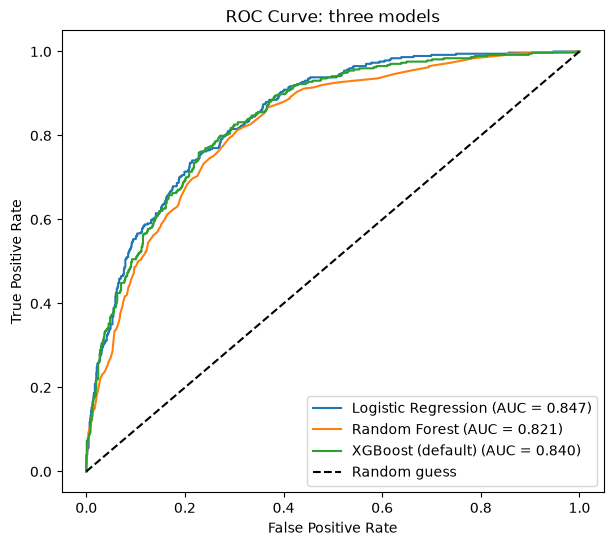

In [277]:
plt.figure(figsize=(7, 6))
for name, prob in [("Logistic Regression", lr_prob), ("Random Forest", rf_prob),
                   ("XGBoost (default)", xgb_prob)]:
    fpr, tpr, _ = roc_curve(Y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(Y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: three models")
plt.legend()
plt.show()

### ROC curve of the three models
All three models are well above random guessing. Logistic Regression and XGBoost are almost on top of each other, and Random Forest is lower. The differences are small, which shows that the features carry most of the signal and the choice of model matters less than the data.

## Hyperparameter Tuning with GridSearchCV
Hyperparameters are settings chosen before training, like tree depth and learning rate. GridSearchCV tries every combination from a small grid, scores each one with 5-fold cross-validation, and keeps the best. I used AUC as the score.

In [278]:
from sklearn.model_selection import GridSearchCV
param_grid={
    "max_depth":[3,5],
    "learning_rate":[0.05,0.1],
    "n_estimators":[100,200],
}

grid=GridSearchCV(
    XGBClassifier(scale_pos_weight=spw,eval_metric="logloss",random_state=42),
    param_grid,cv=5,scoring="roc_auc",n_jobs=-1
)

grid.fit(X_train,Y_train)
print("Best parameters: ",grid.best_params_)
print("Best CV AUC: ",round(grid.best_score_,3))

Best parameters:  {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
Best CV AUC:  0.847


### Grid search result
The grid had 8 combinations (2 values each for max_depth, learning_rate and n_estimators), and each was tested with 5-fold cross-validation, so 40 models were trained. The best parameters are: learning_rate:0.05,max depth:3,n_estimators:100 with a cross-validation AUC of 0.847. I kept the grid small to save time.

In [279]:
xgb_best=grid.best_estimator_
xgb_best_pred=xgb_best.predict(X_test)
xgb_best_prob=xgb_best.predict_proba(X_test)[:,1]
results.append(evaluate("XGBoost (tuned)",Y_test,xgb_best_pred,xgb_best_prob))
pd.DataFrame(results)

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.809,0.679,0.532,0.597,0.847
1,Random Forest,0.787,0.621,0.508,0.559,0.821
2,LR (balanced),0.743,0.510,0.786,0.619,0.847
3,RF (balanced),0.785,0.621,0.487,0.546,0.824
4,XGBoost (default),0.749,0.519,0.786,0.625,0.840
5,XGBoost (tuned),0.748,0.516,0.805,0.629,0.845


### Tuned XGBoost on the test set
After tuning, XGBoost has an AUC of 0.845 on the test set, compared to 0.840 before tuning. The improvement is small, which is normal on this dataset because the default settings were already close to good.

## Model Comparison
Here I compare all models on the same test set to choose the final one.

In [280]:
final_table=pd.DataFrame(results).sort_values("AUC",ascending=False).reset_index(drop=True)
final_table

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.809,0.679,0.532,0.597,0.847
1,LR (balanced),0.743,0.510,0.786,0.619,0.847
2,XGBoost (tuned),0.748,0.516,0.805,0.629,0.845
3,XGBoost (default),0.749,0.519,0.786,0.625,0.840
4,RF (balanced),0.785,0.621,0.487,0.546,0.824
5,Random Forest,0.787,0.621,0.508,0.559,0.821


### Comparison table
The table is sorted by AUC. Logistic Regression, balanced Logistic Regression (both 0.847) and tuned XGBoost (0.845) are almost tied, with a gap of only about 0.002, so AUC alone cannot separate them. Random Forest is clearly lower (about 0.82). The difference is in recall: tuned XGBoost has the highest recall (0.805) and the highest F1 (0.629), while plain Logistic Regression catches only 53.2% of churners. Since missing a churner costs more than a false alarm, recall matters more for ConnectTel.

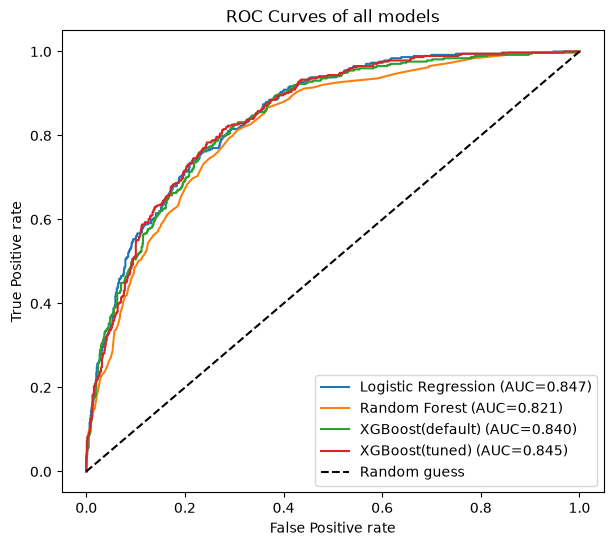

In [281]:
plt.figure(figsize=(7,6))
for name,prob in [("Logistic Regression",lr_prob),("Random Forest",rf_prob),
                  ("XGBoost(default)",xgb_prob),("XGBoost(tuned)",xgb_best_prob)]:
    fpr,tpr,_=roc_curve(Y_test,prob)
    plt.plot(fpr,tpr,label=f"{name} (AUC={roc_auc_score(Y_test,prob):.3f})")
plt.plot([0,1],[0,1],"k--",label="Random guess")
plt.xlabel("False Positive rate")
plt.ylabel("True Positive rate")
plt.title("ROC Curves of all models")
plt.legend()
plt.show()

### ROC curves of all models
All models are well above random guessing and their curves are very close to each other. Logistic Regression (0.847) and tuned XGBoost (0.845) are almost the same, and Random Forest is lower (0.821). This shows that the features carry most of the signal, and the choice of model matters less than the data.

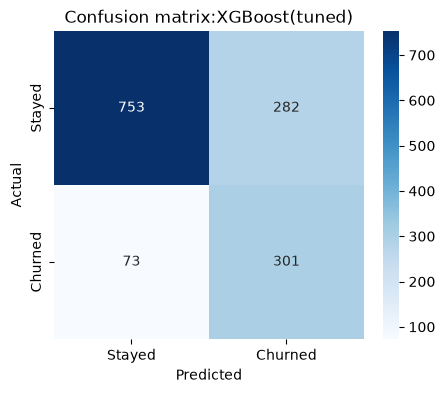

              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.52      0.80      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409



In [282]:
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(Y_test,xgb_best_pred),annot=True,fmt="d",cmap="Blues",
            xticklabels=["Stayed","Churned"],yticklabels=["Stayed","Churned"])
plt.title("Confusion matrix:XGBoost(tuned)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()
print(classification_report(Y_test,xgb_best_pred))


### Final model
I chose tuned XGBoost as my final model. Its AUC (0.845) is almost the same as Logistic Regression (0.847), but it has the highest recall (0.805) and the highest F1 (0.629), and it works well with SHAP for explaining the results. It caught 301 churners and missed 73. It also raised 282 false alarms, which is the price of catching more churners. Logistic Regression with class weights performs almost as well, so a simple model is also a good choice for this data.

## Model Interpretation with SHAP
A high accuracy model is not useful if we cannot explain why a customer is leaving. SHAP gives each feature a value for each customer. A positive value pushes the prediction toward churn and a negative value pushes it toward staying.

In [283]:
import shap
explainer=shap.TreeExplainer(xgb_best)
shap_values=explainer.shap_values(X_test)
print(shap_values.shape)

(1409, 26)


### Computing SHAP values
I used TreeExplainer because the final model is a tree based model (XGBoost). It calculated one SHAP value for every feature of every customer in the test set, so the result has the same shape as X_test.

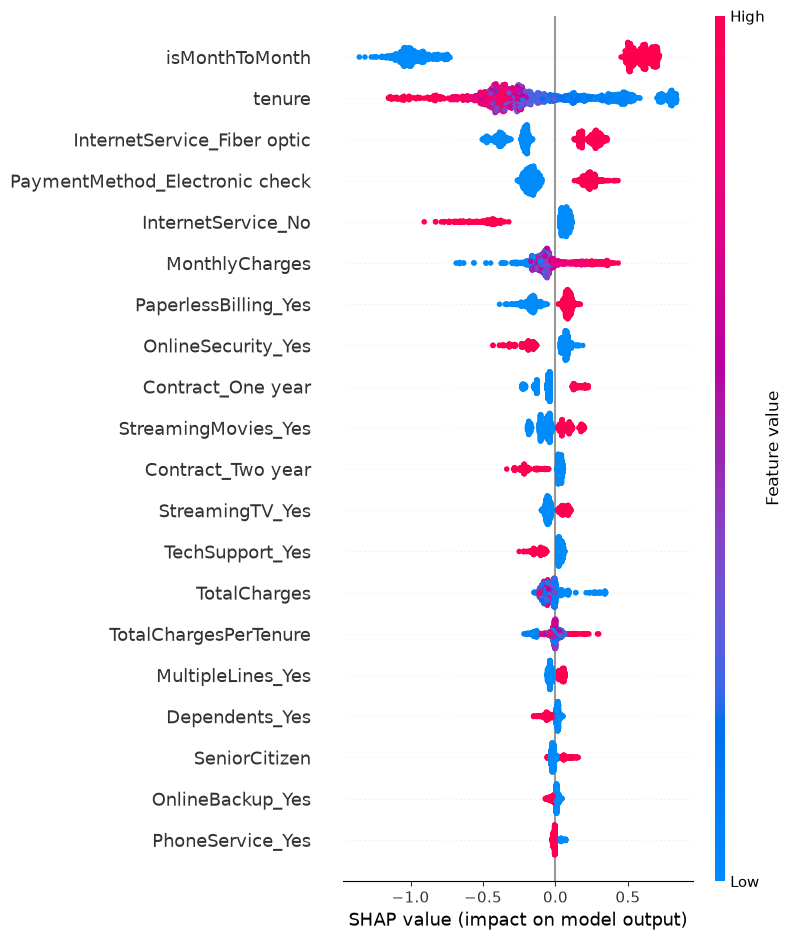

In [284]:
shap.summary_plot(shap_values,X_test)

### SHAP summary plot
Each dot is one customer. Features are sorted from most to least important. A dot on the right pushes toward churn and a dot on the left pushes toward staying. Red means a high value of that feature and blue means a low value.

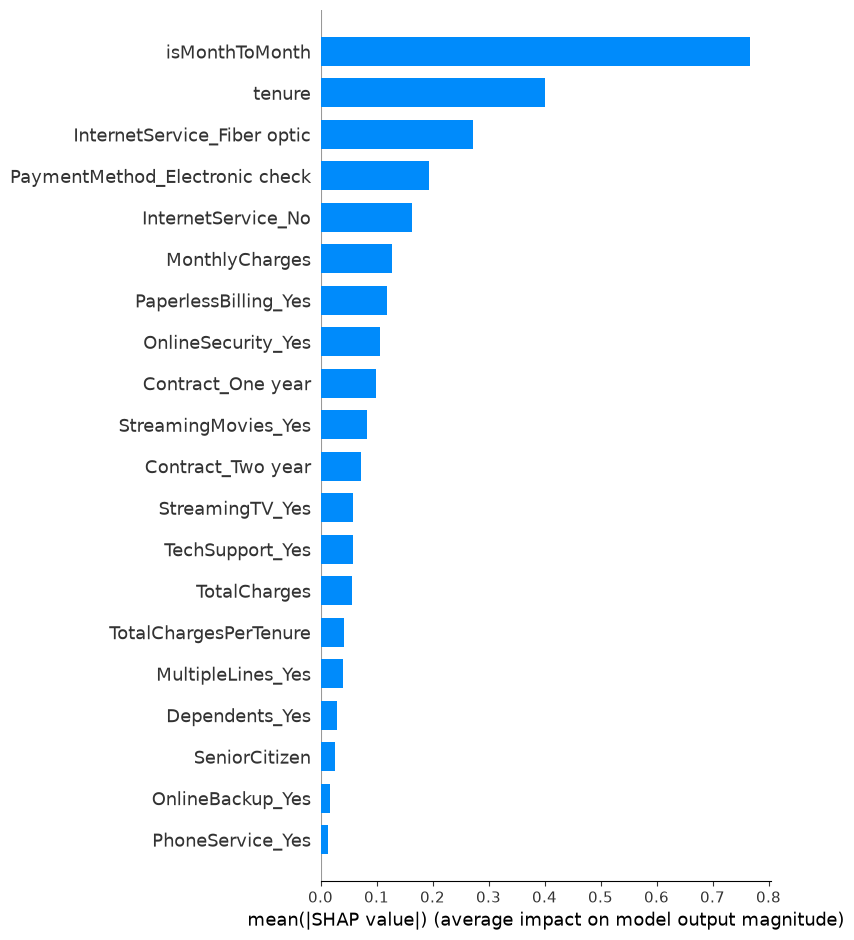

In [285]:
shap.summary_plot(shap_values,X_test,plot_type="bar")

### SHAP feature importance
This bar plot shows the average size of each feature's effect, ignoring direction. The top features are isMonthToMonth,tenure,InternetService_Fiber optic,PaymentMethod_Electronic check,InternetService_No. These agree with my EDA, where contract type, tenure and internet service showed clear differences in churn.

## Which Feature Drives Churn the Most?
The project asks: is the Month-to-Month contract the biggest driver of churn, or is it the high Monthly Charge? I compare the average SHAP effect of each.

In [286]:
imp = pd.Series(np.abs(shap_values).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
print(imp.head(10).round(3))

contract_cols = [c for c in X_test.columns if c.startswith("Contract_")] + ["isMonthToMonth"]
idx = [X_test.columns.get_loc(c) for c in contract_cols]
contract_effect = np.abs(shap_values[:, idx].sum(axis=1)).mean()

print()
print("Contract columns used:", contract_cols)
print("Combined contract effect:", round(contract_effect, 3))
print("MonthlyCharges effect:", round(imp["MonthlyCharges"], 3))
print("tenure effect:", round(imp["tenure"], 3))

isMonthToMonth                    0.767
tenure                            0.400
InternetService_Fiber optic       0.272
PaymentMethod_Electronic check    0.193
InternetService_No                0.163
MonthlyCharges                    0.128
PaperlessBilling_Yes              0.119
OnlineSecurity_Yes                0.106
Contract_One year                 0.099
StreamingMovies_Yes               0.083
dtype: float32

Contract columns used: ['Contract_One year', 'Contract_Two year', 'isMonthToMonth']
Combined contract effect: 0.807
MonthlyCharges effect: 0.128
tenure effect: 0.4


### Contract vs Monthly Charge
Contract information is split across three columns (IsMonthToMonth, Contract_One year and Contract_Two year), so I added their SHAP values together for each customer before comparing. The combined contract effect is 0.807, the effect of MonthlyCharges is 0.128, and tenure is 0.4.

**Answer:** Combined contract effect is larger. 

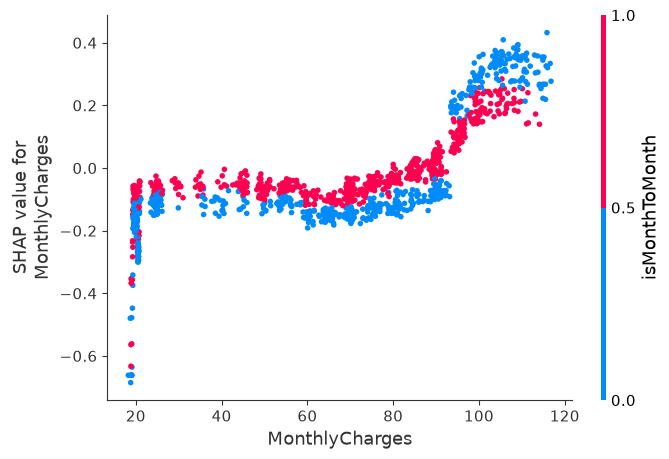

In [287]:
shap.dependence_plot("MonthlyCharges",shap_values,X_test)

### Summary of SHAP analysis
SHAP shows that the main drivers of churn are isMonthToMonth,tenure,InternetService_Fiber optic. New customers, customers without a long contract and customers with high monthly charges are pushed toward churn. Customers with long tenure and one or two year contracts are pushed toward staying. This matches the EDA and gives a clear basis for the business recommendations.

## Business Insight Report
Here I use the EDA, the model and the SHAP results to find the customers who are most at risk of leaving, and to suggest actions for the retention team.

In [288]:
overall = df["Churn"].mean() * 100

groups = {
    "Fiber + month-to-month + high charges": df[(df["InternetService"] == "Fiber optic") &
                                                (df["Contract"] == "Month-to-month") &
                                                (df["MonthlyCharges"] > df["MonthlyCharges"].median())],
    "Month-to-month + electronic check": df[(df["Contract"] == "Month-to-month") &
                                            (df["PaymentMethod"] == "Electronic check")],
    "New customers (tenure 12 or less) + month-to-month": df[(df["tenure"] <= 12) &
                                                             (df["Contract"] == "Month-to-month")],
    "No tech support + no online security": df[(df["TechSupport"] == "No") &
                                               (df["OnlineSecurity"] == "No")],
    "2-year contract": df[df["Contract"] == "Two year"],
}

rows = [{"Group": name, "Customers": len(g), "Churn rate(%)": round(g["Churn"].mean() * 100, 1)}
        for name, g in groups.items()]
rows.append({"Group": "All customers", "Customers": len(df), "Churn rate(%)": round(overall, 1)})

pd.DataFrame(rows).sort_values("Churn rate(%)", ascending=False).reset_index(drop=True)

,Group,Customers,Churn rate(%)
0,Fiber + month-to-month + high charges,1969,54.2
1,Month-to-month + electronic check,1850,53.7
2,New customers (tenure 12 or less) + month-to-m...,1994,51.4
3,No tech support + no online security,2553,49.0
4,All customers,7043,26.5
5,2-year contract,1695,2.8


### High risk groups
The table shows the churn rate of customer groups that came up in the EDA and SHAP results, compared to the overall rate of about 26.5%. The highest risk group is "Month-to-month + electronic check" with a churn rate of 53.7%. The safest group is customers on a two year contract, with a churn rate of 2.8%. These groups give the retention team a clear list of who to target first.

In [289]:
risk = pd.DataFrame({"prob": xgb_best_prob, "actual": Y_test.values})
risk = risk.sort_values("prob", ascending=False).reset_index(drop=True)

n_top = int(0.10 * len(risk))
top_rate = risk.head(n_top)["actual"].mean() * 100
base_rate = risk["actual"].mean() * 100

print("Customers in top 10% risk:", n_top)
print("Churn rate in top 10% risk:", round(top_rate, 1), "%")
print("Churn rate overall (test set):", round(base_rate, 1), "%")
print("Times better than random:", round(top_rate / base_rate, 2))

Customers in top 10% risk: 140
Churn rate in top 10% risk: 75.0 %
Churn rate overall (test set): 26.5 %
Times better than random: 2.83


### Using the model to target customers
I ranked all customers in the test set by the churn probability given by the model. Among the top 10% highest risk customers,75% really churned, compared to 26.5% overall. So contacting these customers is about 2.8 times better than choosing customers at random. This shows how the retention team can use the model: score all customers, and start with the highest probability ones.

In [290]:
print("AUC (tuned XGBoost):", round(roc_auc_score(Y_test, xgb_best_prob), 3))
print("Recall (tuned XGBoost):", round(recall_score(Y_test, xgb_best_pred), 3))
print()
print("Top 3 SHAP features:", imp.head(3).index.tolist())
print()
print(pd.DataFrame(rows))

AUC (tuned XGBoost): 0.845
Recall (tuned XGBoost): 0.805

Top 3 SHAP features: ['isMonthToMonth', 'tenure', 'InternetService_Fiber optic']

                                               Group  Customers  Churn rate(%)
0              Fiber + month-to-month + high charges       1969           54.2
1                  Month-to-month + electronic check       1850           53.7
2  New customers (tenure 12 or less) + month-to-m...       1994           51.4
3               No tech support + no online security       2553           49.0
4                                    2-year contract       1695            2.8
5                                      All customers       7043           26.5


## Business Recommendations

**Summary:** I built and compared Logistic Regression, Random Forest and XGBoost to predict customer churn. The final model is tuned XGBoost with an AUC of 0.845 and a recall of 0.805. SHAP shows that the main drivers of churn are isMonthToMonth,tenure,and InternetService_Fiber optic.

**Recommendations**

- **Offer contract upgrades to month-to-month customers.** Month-to-month customers churn at about 42.7%, compared to about 2.8% for two year contracts. A discount for moving to a one year or two year plan can lock them in.

- **Target high charge Fiber optic customers.** Fiber customers on month-to-month contracts with above median charges churn at 54.2%. Offer them a price review or a loyalty discount, and check the quality of the Fiber service.

- **Focus on the first year.** New customers on month-to-month contracts churn at 51.4%. A welcome offer or a check-in call in the first few months can help them stay.

- **Promote add-on services.** Customers without tech support and online security churn at 49%, while customers who have them churn much less. Offer these services free for a trial period.

- **Move customers away from electronic check.** Customers on month-to-month contracts who pay by electronic check churn at 53.7%. A small discount for automatic payment can reduce this.

- **Use the model every month.** Score all customers and give the retention team the highest probability customers first. The top 10% highest risk customers churn at 75%, which is 2.8 times the average.

**Limits:** The data comes from one company at one point in time. The model shows links, not proof that a feature causes churn, so any offer should first be tested on a small group before a full rollout.